### R² and Inputs for iloop=15

In [3]:
from pathlib import Path
import csv
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "run_simulations.py").exists():
    ROOT = Path(r"C:\Users\aceve\Desktop\HeterogeneousRNNs\new_initial_conditions\positive_currents\positive_currents_ordered")
OUTPUT = ROOT / "seeds_20" / "plots_iloop15"
OUTPUT.mkdir(parents=True, exist_ok=True)
AMPLITUDES = [2, 4, 8, 12, 16, 20]
GSYNS = [0.1, 0.5, 1, 2]
PQIFS = [0, 0.5, 1]
SEEDS = range(10)
ILOOP = 15
ITSTIM, ITMAX = 200, 1000


In [4]:
def experiment_dir(amplitude, gsyn):
    return ROOT / f"seeds_20_ampc_{amplitude:g}_g{gsyn:g}"

def sequence_order(experiment):
    condition = experiment / "condition_000"
    with (condition / "target_parameters.csv").open(newline="") as file:
        rows = list(csv.DictReader(file))
    return np.array([int(row["neuron_index"]) for row in sorted(rows, key=lambda row: float(row["sequence_position"]))])

def load_target(experiment):
    condition = experiment / "condition_000"
    # target_values.npy is already stored in physical neuron-index order.
    # Do not apply target_parameters sequence_position as a second permutation.
    target = np.load(condition / "target_values.npy").astype(float)
    return target[:, ITSTIM:ITMAX]

def input_path(experiment, pqif, seed):
    return (experiment / "condition_000" / "simulation_1" / "inputs" /
            f"simulation_1_inputs_pqif_{pqif}_iloop_{ILOOP}_seed_{seed}.npz")

records = []
seed_inputs_by_key = {}
for amplitude in AMPLITUDES:
    for gsyn in GSYNS:
        experiment = experiment_dir(amplitude, gsyn)
        if not (experiment / "experiment.json").exists():
            raise FileNotFoundError(experiment)
        target = load_target(experiment)
        for pqif in PQIFS:
            r2_values = []
            seed_inputs = {}
            for seed in SEEDS:
                inputs = np.load(input_path(experiment, pqif, seed))["inputs"].T.astype(float)
                inputs = inputs[:, ITSTIM:ITMAX]
                error = inputs - target
                denominator = np.sum((target - target.mean()) ** 2)
                r2_values.append(float(1 - np.sum(error ** 2) / denominator))
                seed_inputs[seed] = inputs
                records.append({"amplitude": amplitude, "gsyn": gsyn, "pqif": pqif, "seed": seed, "r2": r2_values[-1]})
            seed_inputs_by_key[(amplitude, gsyn, pqif)] = seed_inputs

r2_by_seed = pd.DataFrame(records)
r2_summary = (r2_by_seed.groupby(["amplitude", "gsyn", "pqif"], as_index=False)["r2"]
              .agg(r2_mean="mean", r2_sd="std", r2_min="min", r2_max="max"))
r2_summary.head()


,amplitude,gsyn,pqif,r2_mean,r2_sd,r2_min,r2_max
0,2,0.1,0.0,0.502114,0.140393,0.338885,0.842978
1,2,0.1,0.5,0.481901,0.657094,-1.277141,0.932410
2,2,0.1,1.0,0.664565,0.300562,0.154238,0.916112
3,2,0.5,0.0,0.428696,0.079764,0.305223,0.587763
4,2,0.5,0.5,0.728119,0.250724,0.302533,0.940615


## R² by Parameter Combination

Each cell shows the mean R² across the 20 seeds for `iloop=15`

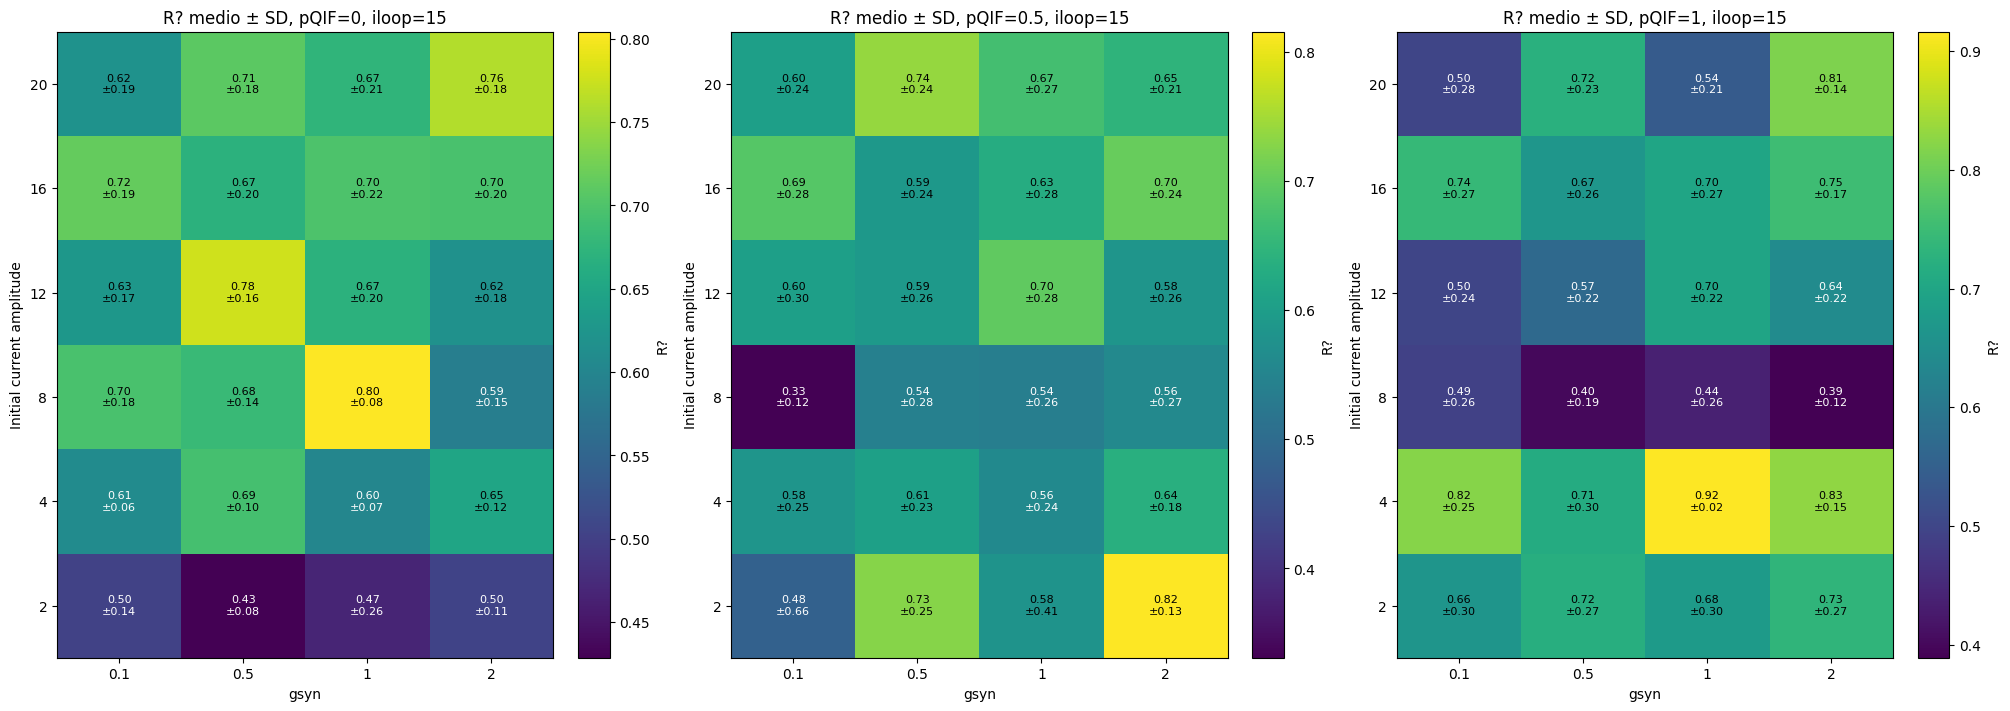

In [5]:
def r2_matrix(pqif=None):
    data = r2_summary if pqif is None else r2_summary[r2_summary.pqif == pqif]
    if pqif is None:
        data = (data.groupby(["amplitude", "gsyn"], as_index=False)["r2_mean"].mean())
    return (data.pivot(index="amplitude", columns="gsyn", values="r2_mean")
            .reindex(index=AMPLITUDES, columns=GSYNS).to_numpy())

def r2_sd_matrix(pqif):
    data = r2_summary[r2_summary.pqif == pqif]
    return (data.pivot(index="amplitude", columns="gsyn", values="r2_sd")
            .reindex(index=AMPLITUDES, columns=GSYNS).to_numpy())

def draw_heatmap(ax, values, title, deviations):
    image = ax.imshow(values, origin="lower", aspect="auto", cmap="viridis",
                      vmin=np.nanmin(values), vmax=np.nanmax(values))
    ax.set_xticks(range(len(GSYNS)), [f"{g:g}" for g in GSYNS])
    ax.set_yticks(range(len(AMPLITUDES)), [f"{a:g}" for a in AMPLITUDES])
    ax.set_xlabel("gsyn")
    ax.set_ylabel("Initial current amplitude")
    ax.set_title(title)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            ax.text(j, i, f"{values[i,j]:.2f}\n±{deviations[i,j]:.2f}", ha="center", va="center",
                    color="white" if values[i,j] < (np.nanmin(values)+np.nanmax(values))/2 else "black", fontsize=8)
    return image

fig, axes = plt.subplots(1, 3, figsize=(20, 7), constrained_layout=True)
for ax, pqif in zip(axes, PQIFS):
    image = draw_heatmap(ax, r2_matrix(pqif), f"R? medio ± SD, pQIF={pqif:g}, iloop=15", r2_sd_matrix(pqif))
    fig.colorbar(image, ax=ax, label="R?")
fig.savefig(OUTPUT / "r2_iloop15_heatmaps.png", dpi=180)
plt.show()


## Inputs for All Neurons for Each Parameter Combination

Each panel shows an `imshow` plot of all neurons versus time, averaged across the 20 seeds, for each amplitude–`gsyn` pair. A separate figure is generated for each `pQIF` value.

In [ ]:
sequence_indices = sequence_order(experiment_dir(AMPLITUDES[0], GSYNS[0]))
for seed in SEEDS:
    for pqif in PQIFS:
        fig, axes = plt.subplots(len(AMPLITUDES), len(GSYNS), figsize=(16, 20), sharex=True, sharey=True, constrained_layout=True)
        for row, amplitude in enumerate(AMPLITUDES):
            for col, gsyn in enumerate(GSYNS):
                ax = axes[row, col]
                values = seed_inputs_by_key[(amplitude, gsyn, pqif)][seed][sequence_indices, :]
                image = ax.imshow(values, aspect="auto", origin="lower", cmap="viridis")
                ax.set_title(f"ampc={amplitude:g}, g={gsyn:g}")
                if row == len(AMPLITUDES)-1: ax.set_xlabel("timestep")
                if col == 0: ax.set_ylabel("neuron")
        fig.suptitle(f"Inputs: seed={seed}, pQIF={pqif:g}, iloop=15")
        fig.colorbar(image, ax=axes, label="input", shrink=0.8)
        fig.savefig(OUTPUT / f"inputs_iloop15_seed_{seed}_pqif_{pqif:g}.png", dpi=180)
        plt.close(fig)


In [ ]:
r2_by_seed.to_csv(OUTPUT / "r2_iloop15_by_seed.csv", index=False)
r2_summary.to_csv(OUTPUT / "r2_iloop15_summary.csv", index=False)
print(f"Records: {len(r2_by_seed)}")
print(f"Figures and tables saved in: {OUTPUT}")
print(r2_summary.sort_values("r2_mean", ascending=False).head(10).to_string(index=False))
